# Task 4: Monthly business metrics

Six metrics are defined with exact populations and formulas. Completed stays use `reservation_status = Check-Out`; No-Shows never count as nights sold or revenue.


In [1]:
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid')

DATA_DIR = Path('../data')
OUTPUT_DIR = Path('../outputs')
SLIDE_DIR = Path('../slides')
MODEL_DIR = Path('../models')
for folder in [DATA_DIR, OUTPUT_DIR, SLIDE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


In [2]:
df = pd.read_csv(DATA_DIR / 'hotel_bookings_clustered.csv', parse_dates=['arrival_date'])
df['year_month'] = df['arrival_date'].dt.to_period('M')
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
completed = df[df['reservation_status'].eq('Check-Out')].copy()
completed['room_revenue_est'] = completed['adr'] * completed['total_nights']
arrivals = df[df['reservation_status'].isin(['Check-Out','No-Show'])].copy()


## Metric definitions

1. **Cancellation rate:** cancelled or No-Show bookings divided by all bookings. Lower is better.
2. **Weighted ADR:** estimated lodging revenue divided by completed room nights. Higher is better within demand and service constraints.
3. **Nights sold:** completed room nights. Higher is generally better; capacity is unavailable.
4. **Estimated lodging revenue:** ADR multiplied by completed nights. Higher is better.
5. **Average lead time:** average days from booking to arrival for all bookings. Direction depends on cancellation risk.
6. **No-Show rate:** No-Shows divided by Check-Out plus No-Show arrivals. Lower is better.


In [3]:
base = df.groupby('year_month').agg(
    bookings=('source_row_id','size'),
    cancellations=('is_canceled','sum'),
    avg_lead_time=('lead_time','mean'),
)
base['cancellation_rate'] = base['cancellations'] / base['bookings']

stay = completed.groupby('year_month').agg(
    nights_sold=('total_nights','sum'),
    estimated_revenue=('room_revenue_est','sum'),
)
stay['weighted_adr'] = stay['estimated_revenue'] / stay['nights_sold']

noshow = arrivals.groupby('year_month').agg(
    arrivals=('source_row_id','size'),
    no_shows=('no_show_flag','sum'),
)
noshow['no_show_rate'] = noshow['no_shows'] / noshow['arrivals']

monthly = base.join(stay).join(noshow).reset_index()
monthly.to_csv(OUTPUT_DIR / 'monthly_metrics.csv', index=False)
display(monthly.round(3))

segment_metrics = df.groupby('cluster_name').agg(
    bookings=('source_row_id','size'),
    cancellation_rate=('is_canceled','mean'),
    avg_lead_time=('lead_time','mean'),
)
seg_stay = completed.groupby('cluster_name').agg(
    nights_sold=('total_nights','sum'),
    estimated_revenue=('room_revenue_est','sum'),
)
seg_stay['weighted_adr'] = seg_stay['estimated_revenue'] / seg_stay['nights_sold']
seg_noshow = arrivals.groupby('cluster_name')['no_show_flag'].mean().rename('no_show_rate')
segment_metrics = segment_metrics.join(seg_stay).join(seg_noshow)
segment_metrics.to_csv(OUTPUT_DIR / 'segment_metrics.csv')
display(segment_metrics.round(3))


   year_month  bookings  cancellations  ...  arrivals  no_shows  no_show_rate
0     2015-07      2774           1259  ...      1542        27         0.018
1     2015-08      3883           1598  ...      2305        20         0.009
2     2015-09      5109           2093  ...      3054        38         0.012
3     2015-10      4951           1732  ...      3237        18         0.006
4     2015-11      2337            486  ...      1890        39         0.021
5     2015-12      2913            973  ...      1989        49         0.025
6     2016-01      2248            557  ...      1741        50         0.029
7     2016-02      3884           1335  ...      2693       144         0.053
8     2016-03      4819           1477  ...      3413        71         0.021
9     2016-04      5425           2060  ...      3419        54         0.016
10    2016-05      5475           1915  ...      3625        65         0.018
11    2016-06      5290           2096  ...      3244        50 

   year_month  bookings  cancellations  ...  arrivals  no_shows  no_show_rate
0     2015-07      2774           1259  ...      1542        27         0.018
1     2015-08      3883           1598  ...      2305        20         0.009
2     2015-09      5109           2093  ...      3054        38         0.012
3     2015-10      4951           1732  ...      3237        18         0.006
4     2015-11      2337            486  ...      1890        39         0.021
5     2015-12      2913            973  ...      1989        49         0.025
6     2016-01      2248            557  ...      1741        50         0.029
7     2016-02      3884           1335  ...      2693       144         0.053
8     2016-03      4819           1477  ...      3413        71         0.021
9     2016-04      5425           2060  ...      3419        54         0.016
10    2016-05      5475           1915  ...      3625        65         0.018
11    2016-06      5290           2096  ...      3244        50 

                           bookings  ...  no_show_rate
cluster_name                         ...              
Early planners                 5723  ...         0.056
Long-stay guests             102917  ...         0.018
Loyal repeat guests            3798  ...         0.013
Short-lead standard stays      6771  ...         0.000

[4 rows x 7 columns]

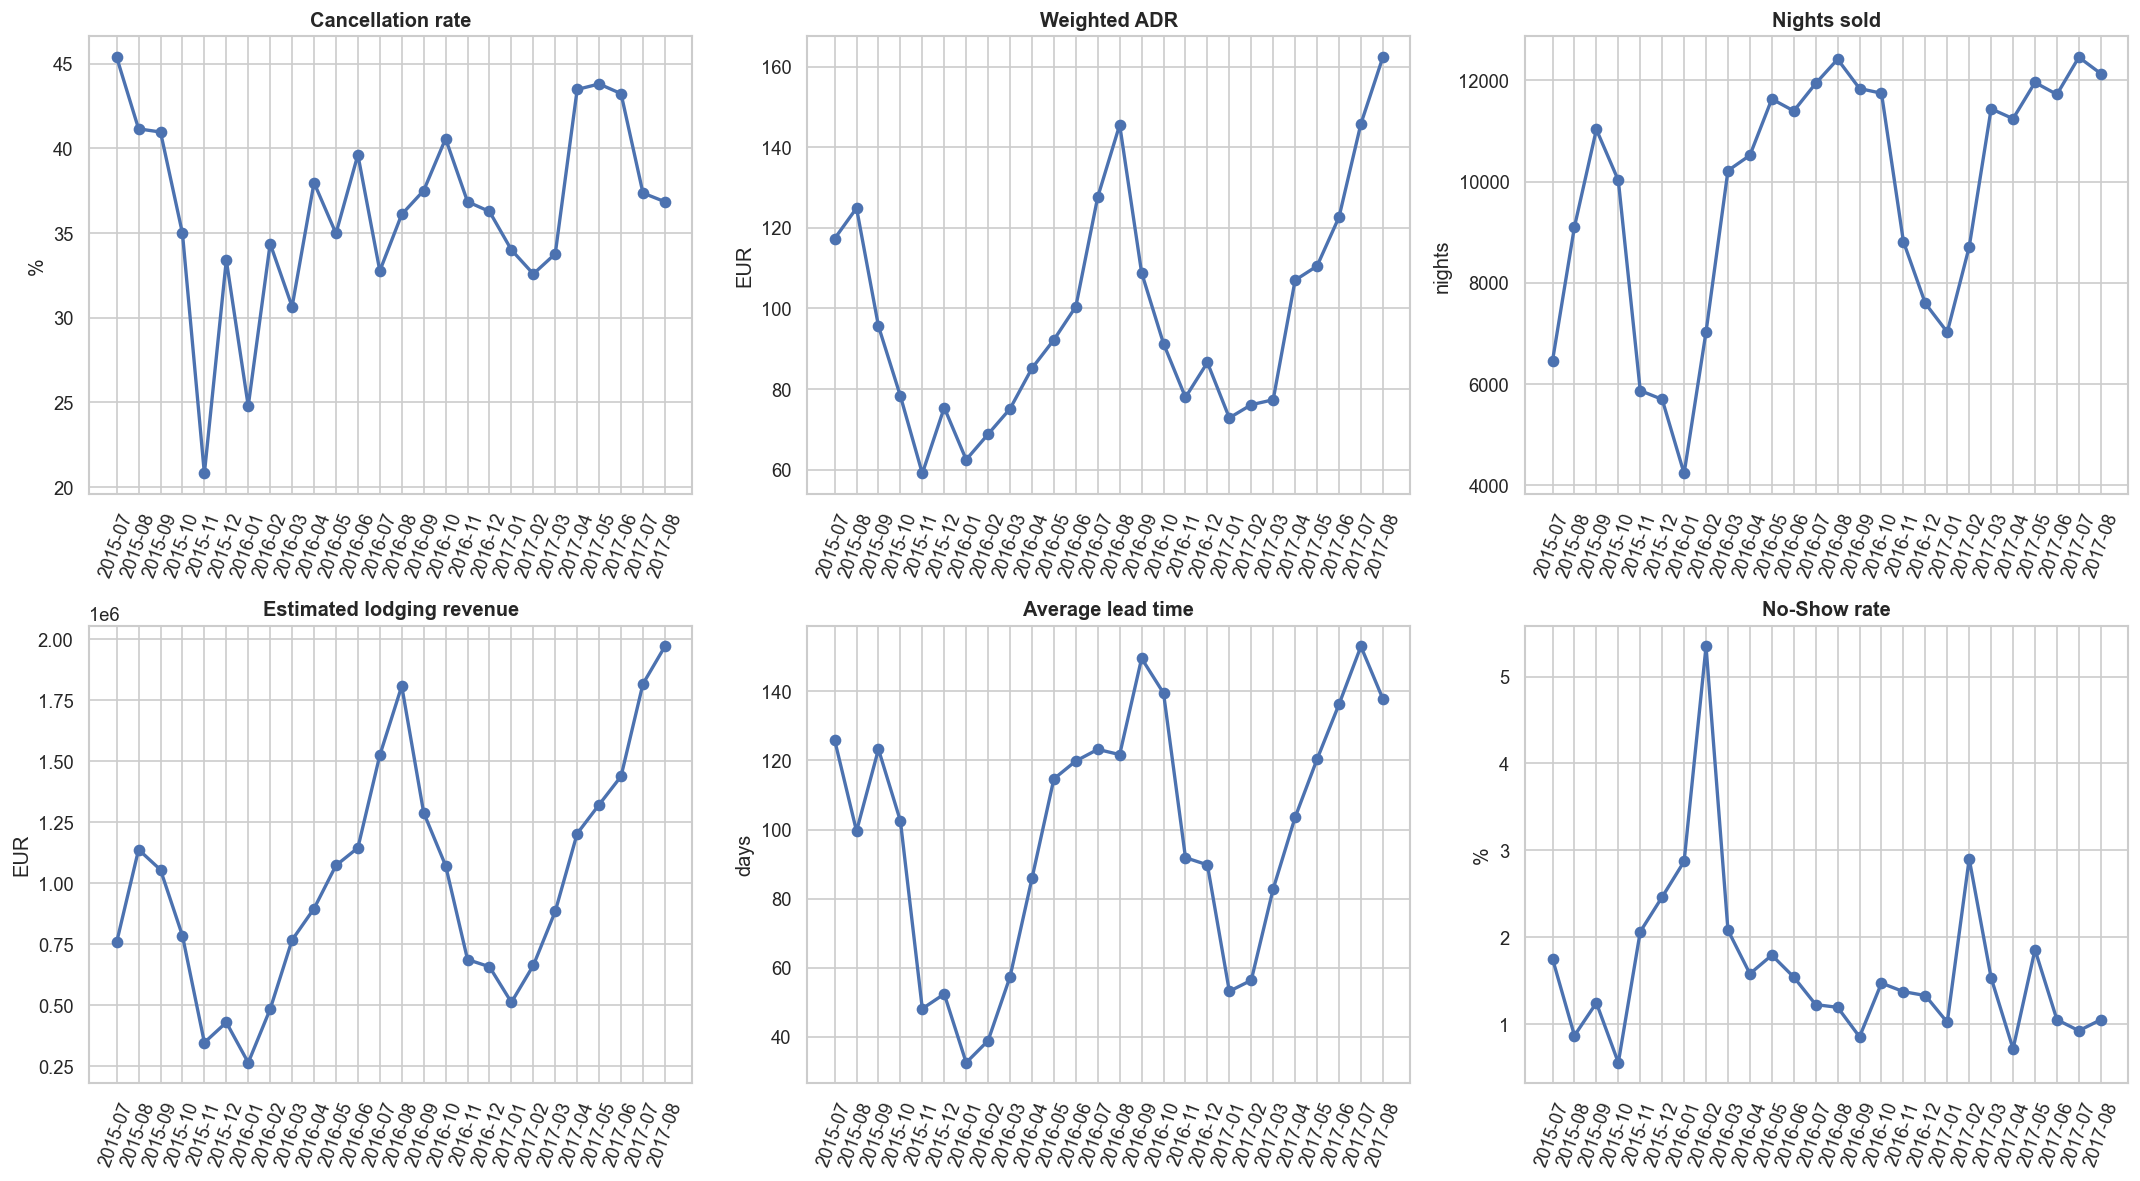

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
specs = [
    ('cancellation_rate','Cancellation rate','%'),
    ('weighted_adr','Weighted ADR','EUR'),
    ('nights_sold','Nights sold','nights'),
    ('estimated_revenue','Estimated lodging revenue','EUR'),
    ('avg_lead_time','Average lead time','days'),
    ('no_show_rate','No-Show rate','%'),
]
x = monthly['year_month'].astype(str)
for ax, (col, title, unit) in zip(axes.ravel(), specs):
    y = monthly[col] * 100 if unit == '%' else monthly[col]
    ax.plot(x, y, marker='o', linewidth=2)
    ax.set_title(title, fontweight='bold'); ax.set_ylabel(unit); ax.tick_params(axis='x', rotation=70)
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'monthly_metrics_final.png', bbox_inches='tight'); plt.show()


## Unusual months and rolling forecast

A three-month moving average predicts each of the final three months using information available before that month. This is a rolling one-step-ahead check, not a simultaneous three-month forecast.


In [5]:
high_cancel = monthly.nlargest(3, 'cancellation_rate')[['year_month','cancellation_rate']]
high_revenue = monthly.nlargest(3, 'estimated_revenue')[['year_month','estimated_revenue']]
display(high_cancel); display(high_revenue)

series = monthly['cancellation_rate'].to_numpy()
train = list(series[:-3]); actual = series[-3:]; forecasts = []
for value in actual:
    forecasts.append(float(np.mean(train[-3:])))
    train.append(float(value))
forecast_df = pd.DataFrame({
    'month': monthly['year_month'].astype(str).iloc[-3:].to_numpy(),
    'actual': actual,
    'forecast': forecasts,
})
forecast_df['absolute_error'] = (forecast_df['actual'] - forecast_df['forecast']).abs()
display(forecast_df)
forecast_df.to_csv(OUTPUT_DIR / 'metric_forecast.csv', index=False)
print('Forecast MAE:', f"{forecast_df['absolute_error'].mean():.2%}")


   year_month  cancellation_rate
0     2015-07           0.453857
22    2017-05           0.438065
21    2017-04           0.434813
   year_month  estimated_revenue
25    2017-08         1970181.60
24    2017-07         1816730.61
13    2016-08         1807654.15
     month    actual  forecast  absolute_error
0  2017-06  0.432346  0.403530        0.028816
1  2017-07  0.373635  0.435075        0.061440
2  2017-08  0.368475  0.414682        0.046207
Forecast MAE: 4.55%


   year_month  cancellation_rate
0     2015-07           0.453857
22    2017-05           0.438065
21    2017-04           0.434813

   year_month  estimated_revenue
25    2017-08         1970181.60
24    2017-07         1816730.61
13    2016-08         1807654.15

     month    actual  forecast  absolute_error
0  2017-06  0.432346  0.403530        0.028816
1  2017-07  0.373635  0.435075        0.061440
2  2017-08  0.368475  0.414682        0.046207